# Example of the `aitlas` toolbox in the context of multi label image classification

This notebook shows a sample implementation of a multi label image classification using the `aitlas` toolbox using the Big Earth Net multi label dataset with 19 labels.

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets.bigearthnet_43 import BigEarthNetDataset
from aitlas.models import ResNet50MultiLabel
from aitlas.transforms import ResizeCenterCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "lmdb_path": "./data/BigEarthNet/lmdb",
    "import_to_lmdb": "false",
    "csv_file": "./data/BigEarthNet/train.csv",
    "data_dir": "./data/BigEarthNet/BigEarthNet-v1.0",
    "selection": "rgb",
    "version": "43 labels",
}
dataset = BigEarthNetDataset(dataset_config)

## Show images from the dataset

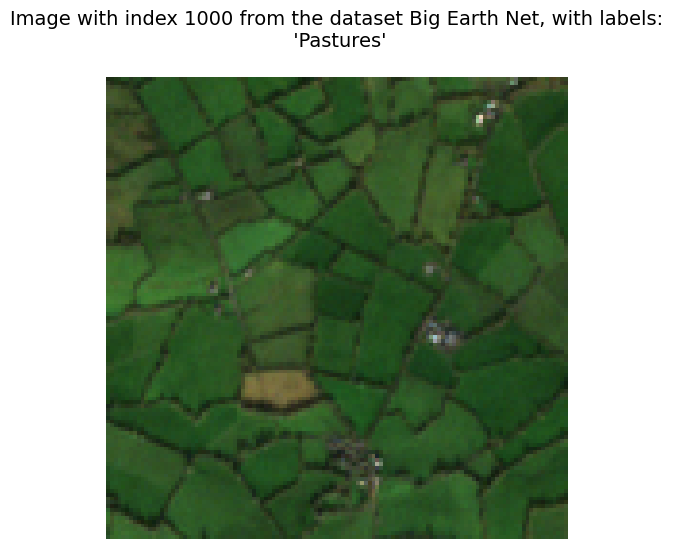

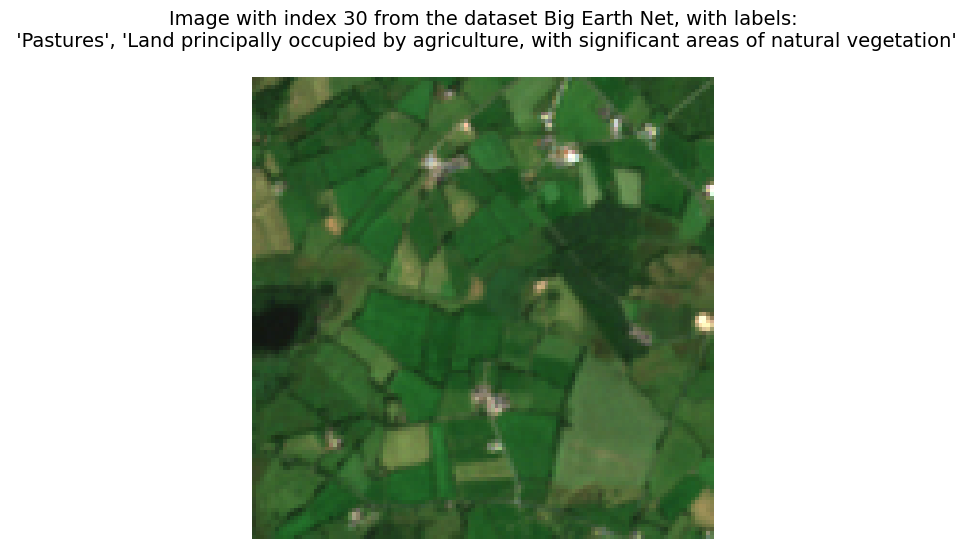

In [5]:
fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(30)

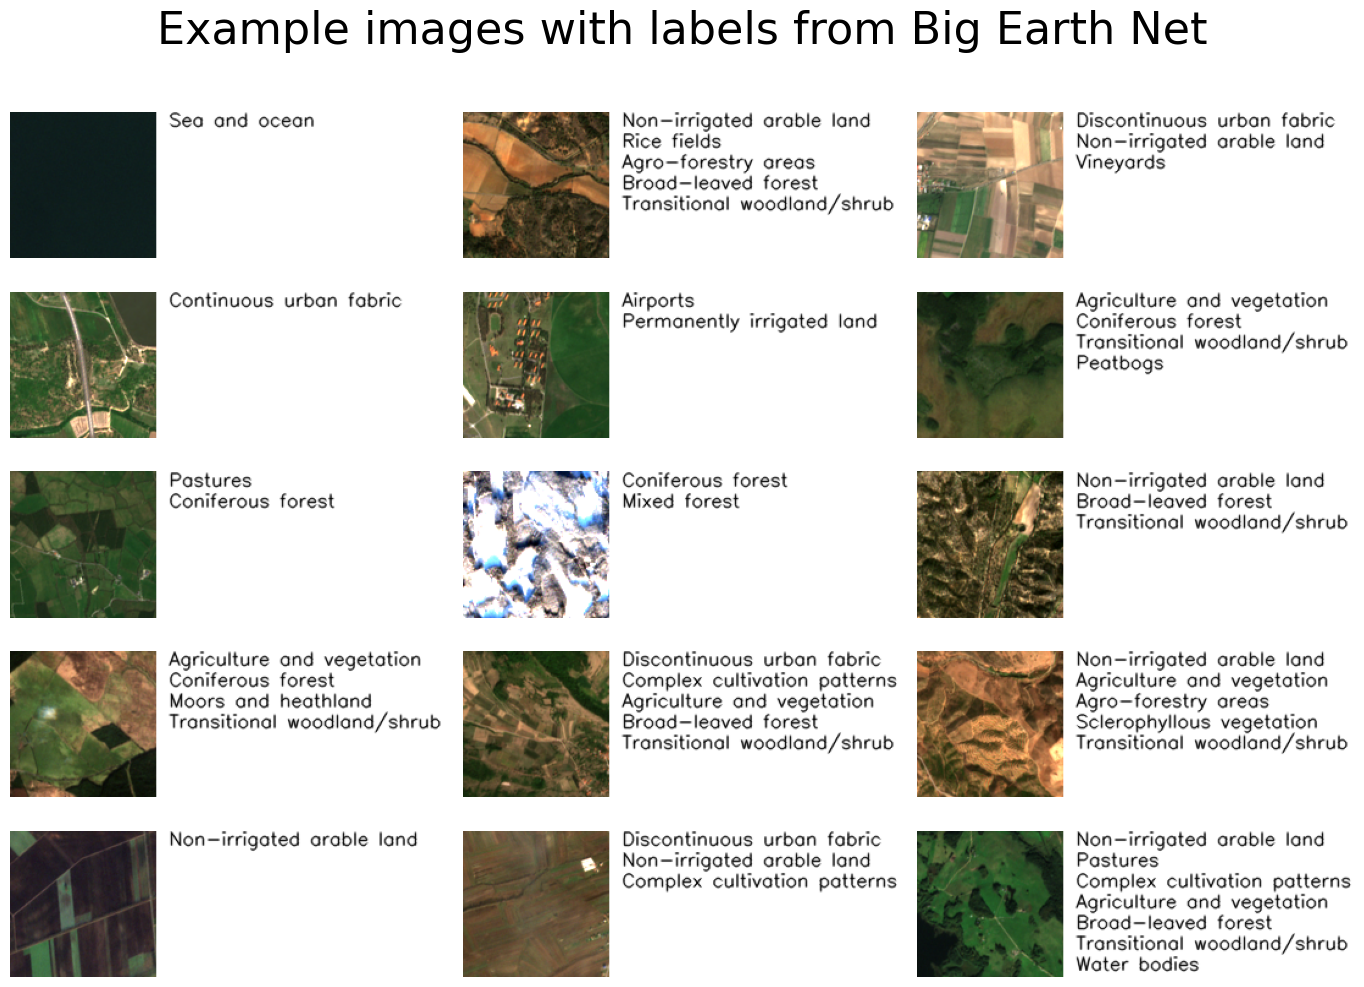

In [6]:
fig3 = dataset.show_batch(15)

## Inspect the data

In [7]:
dataset.labels_stats()

Processed 100000 of 269695
Processed 200000 of 269695


'Minimum number of labels: 1.0, Maximum number of labels: 12.0, Average number of labels: 2.9921207289716163'

In [8]:
dataset.data_distribution_table()

Processed 100000 of 269695
Processed 200000 of 269695


,Label,Count
0,Continuous urban fabric,5498
1,Discontinuous urban fabric,34198
2,Industrial or commercial units,6182
3,Road and rail networks and associated land,2577
4,Port areas,320
5,Airports,600
6,Mineral extraction sites,3470
7,Dump sites,684
8,Construction sites,868
9,Green urban areas,1187


Processed 100000 of 269695
Processed 200000 of 269695


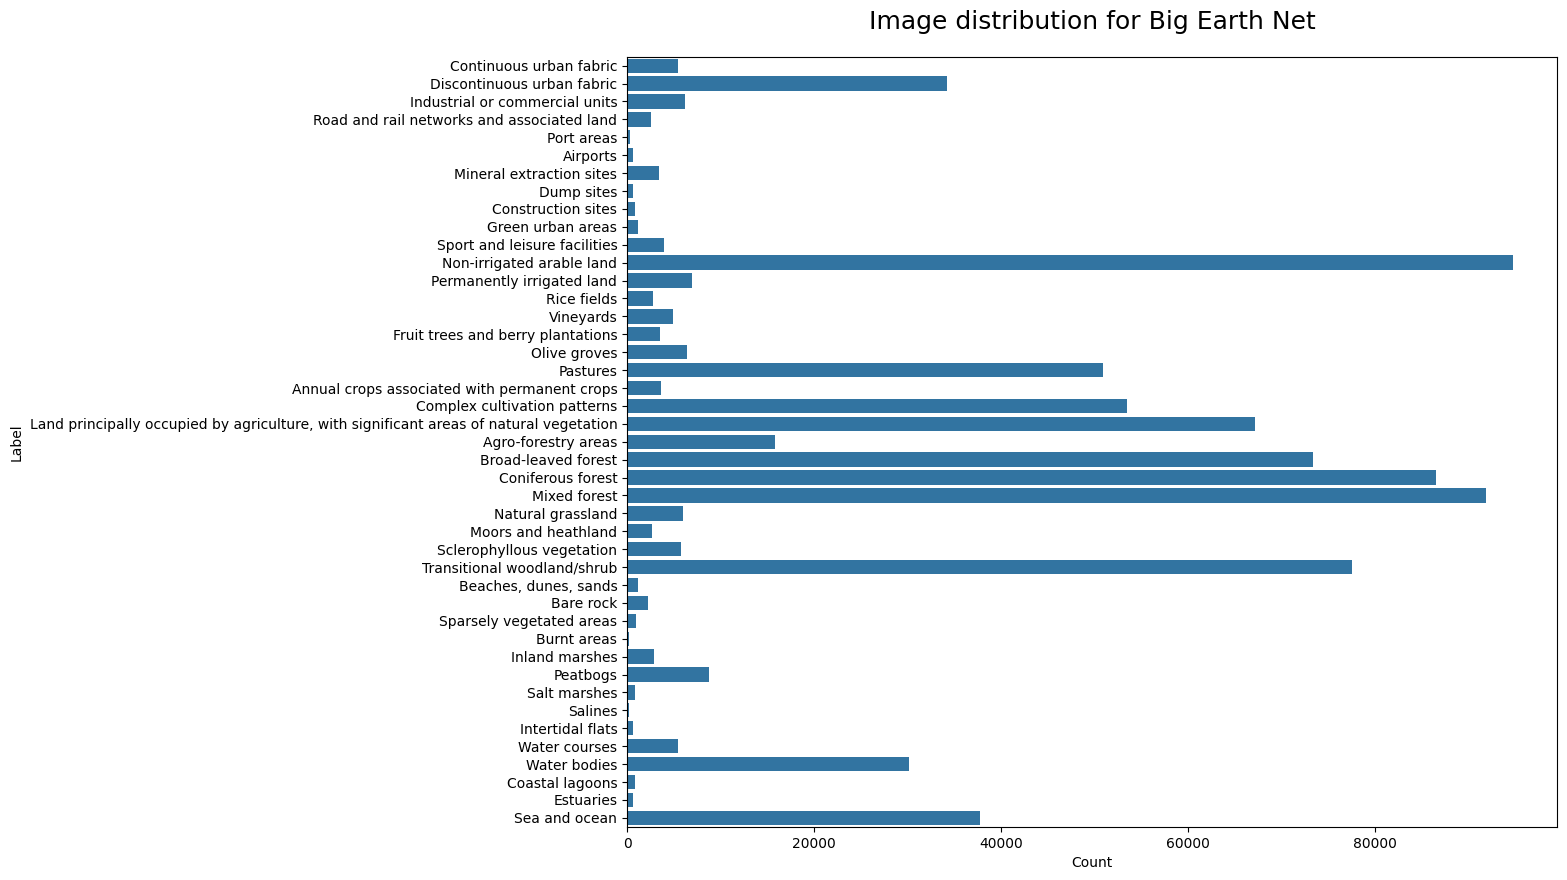

In [9]:
dataset.data_distribution_barchart();

## Load train and test splits

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "lmdb_path": "./data/BigEarthNet/lmdb",
    "import_to_lmdb": "false",
    "csv_file": "./data/BigEarthNet/train.csv",
    "data_dir": "./data/BigEarthNet/BigEarthNet-v1.0",
    "transforms": ["aitlas.transforms.big_earth_net.ResizeToTensorNormalizeRGB"],
    "bands10_mean": [429.9430203, 614.21682446, 590.23569706],
    "bands10_std": [572.41639287, 582.87945694, 675.88746967],
    "selection": "rgb",
    "version": "43 labels",
}

train_dataset = BigEarthNetDataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor()

test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "lmdb_path": "./data/BigEarthNet/lmdb",
    "import_to_lmdb": "false",
    "csv_file": "./data/BigEarthNet/val.csv",
    "data_dir": "./data/BigEarthNet/BigEarthNet-v1.0",
    "transforms": ["aitlas.transforms.big_earth_net.ResizeToTensorNormalizeRGB"],
    "bands10_mean": [429.9430203, 614.21682446, 590.23569706],
    "bands10_std": [572.41639287, 582.87945694, 675.88746967],
    "selection": "rgb",
    "version": "43 labels",
}

test_dataset = BigEarthNetDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(269695, 123723)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/BigEarthNet/experiments_43"
model_config = {
    "num_classes": 43,
    "learning_rate": 0.0001,
    "pretrained": False,
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score"],
}
model = ResNet50MultiLabel(model_config)
model.prepare()

## Training and evaluation

In [9]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id="1",
)

2026-08-24 07:34:44,255 INFO Starting training.
training: 100%|██████████| 16856/16856 [09:07<00:00, 30.79it/s]
2026-08-24 07:43:51,683 INFO epoch: 1, time: 547, loss:  0.12871
testing on train set: 100%|██████████| 16856/16856 [05:41<00:00, 49.36it/s]
2026-08-24 07:49:34,036 INFO Accuracy:0.9567193259224352, Accuracy per Class:[0.98226144 0.92338382 0.97784905 0.99035948 0.99879494 0.99777526
 0.98714845 0.9974638  0.99678155 0.99458277 0.9851091  0.84507314
 0.97454161 0.98987004 0.98186841 0.9870335  0.97631769 0.88723187
 0.98564304 0.83735331 0.80467936 0.96427446 0.83380115 0.8814661
 0.8307273  0.97817905 0.98997386 0.97873524 0.75070728 0.99634773
 0.98788261 0.99644784 0.99909898 0.98898014 0.96995866 0.99662211
 0.99912865 0.99761583 0.97889468 0.94073305 0.99785684 0.99721908
 0.98315875], Precision Micro:0.7492625224103301, Precision Macro:0.4729544674320054, Precision Weighted:0.7317686329864677, Precision per Class:[0.63261516 0.78072759 0.54561404 0.30508475 0.         0

0.08152250254471793

## Predictions

2026-08-24 12:40:09,510 INFO Loading checkpoint /home/dragik/data/BigEarthNet/experiments_43/checkpoint.pth.tar
2026-08-24 12:40:10,406 INFO Loaded checkpoint /home/dragik/data/BigEarthNet/experiments_43/checkpoint.pth.tar at epoch 11


125866


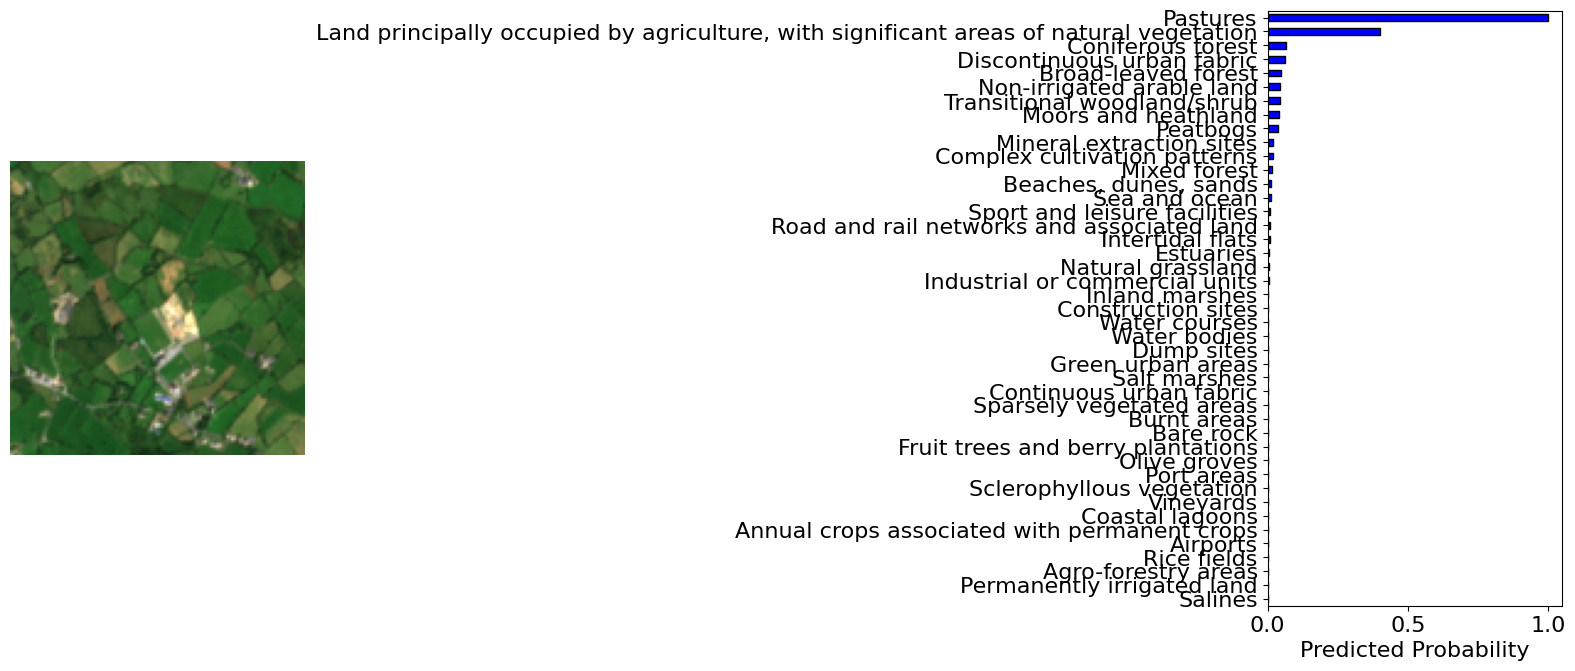

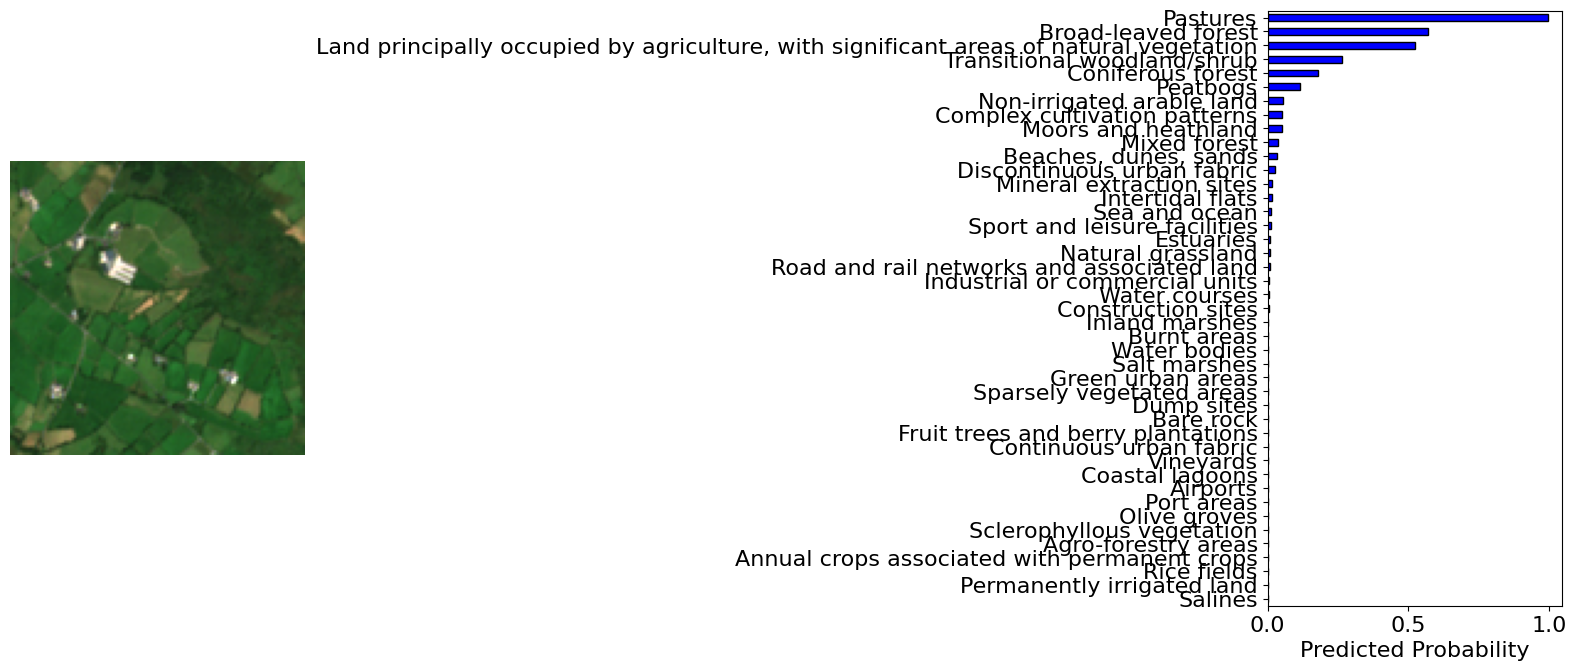

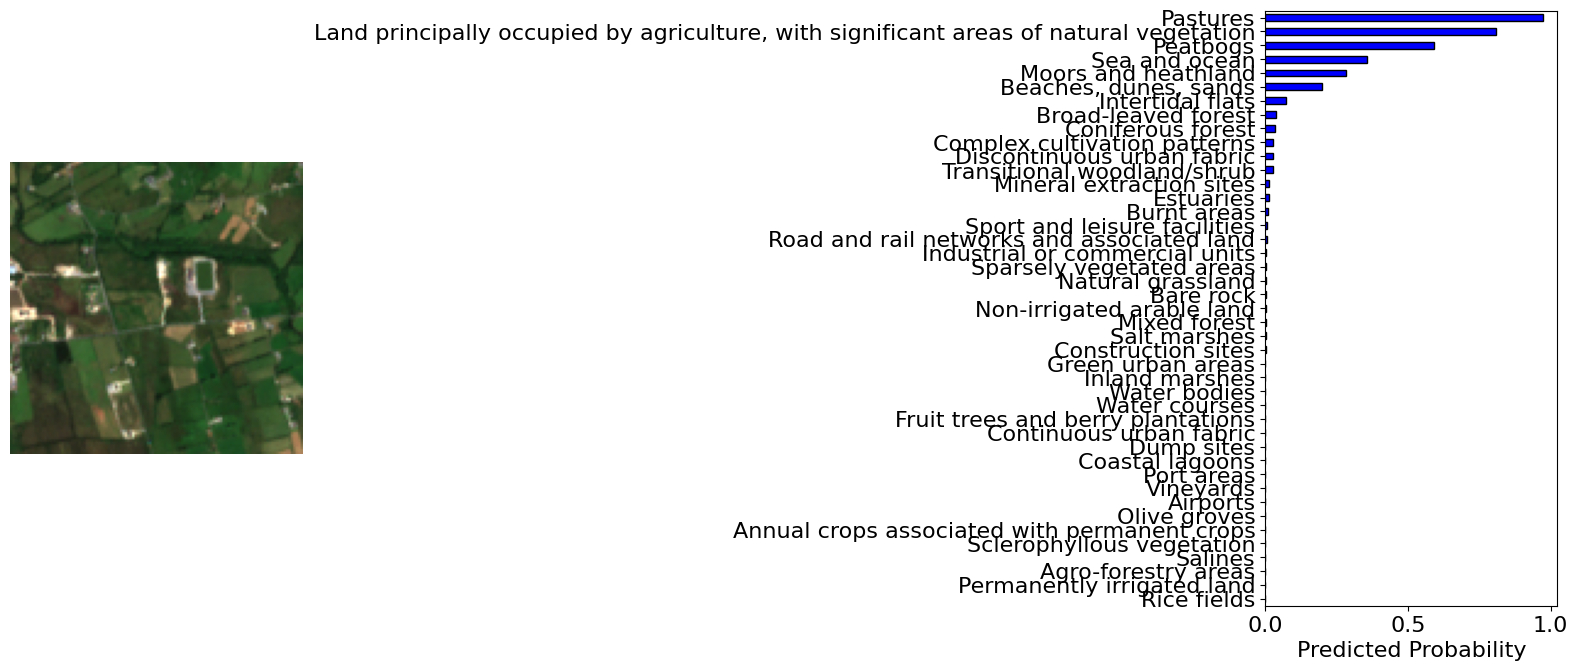

In [ ]:
model_path = "./data/BigEarthNet/experiments_43/checkpoint.pth.tar"
labels = ["Continuous urban fabric","Discontinuous urban fabric","Industrial or commercial units","Road and rail networks and associated land",
          "Port areas","Airports","Mineral extraction sites","Dump sites","Construction sites","Green urban areas","Sport and leisure facilities",
          "Non-irrigated arable land","Permanently irrigated land","Rice fields","Vineyards","Fruit trees and berry plantations","Olive groves",
          "Pastures","Annual crops associated with permanent crops","Complex cultivation patterns",
          "Land principally occupied by agriculture, with significant areas of natural vegetation","Agro-forestry areas","Broad-leaved forest",
          "Coniferous forest","Mixed forest","Natural grassland","Moors and heathland","Sclerophyllous vegetation","Transitional woodland/shrub",
          "Beaches, dunes, sands","Bare rock","Sparsely vegetated areas","Burnt areas","Inland marshes","Peatbogs","Salt marshes","Salines",
          "Intertidal flats","Water courses","Water bodies","Coastal lagoons","Estuaries","Sea and ocean"]

model.load_model(model_path)
transform = ResizeCenterCropFlipHVToTensor()

test_dataset_config = {
    "lmdb_path": "./data/BigEarthNet/lmdb",
    "import_to_lmdb": "false",
    "csv_file": "./data/BigEarthNet/test.csv",
    "data_dir": "./data/BigEarthNet/BigEarthNet-v1.0",
    "selection": "rgb",
    "version": "43 labels",
}

test_dataset = BigEarthNetDataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[100][0]
fig = model.predict_image(image, labels, transform)